In [38]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split

from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

In [4]:
df = pd.read_csv('..\\data\\course_lead_scoring_2026.csv')

In [5]:
df.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [9]:
categorical_columns = list(df.dtypes[df.dtypes == 'str'].index)
numerical_columns = list(df.dtypes[df.dtypes != 'str'].index)


In [11]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   lead_source               4852 non-null   str    
 1   industry                  4760 non-null   str    
 2   employment_status         4806 non-null   str    
 3   location                  4792 non-null   str    
 4   annual_income             4631 non-null   float64
 5   number_of_courses_viewed  5000 non-null   int64  
 6   interaction_count         5000 non-null   int64  
 7   lead_score                4965 non-null   float64
 8   converted                 5000 non-null   int64  
dtypes: float64(2), int64(3), str(4)
memory usage: 351.7 KB


In [10]:
df.isna().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [12]:
df[categorical_columns] = df[categorical_columns].fillna('NA')
df[numerical_columns] = df[numerical_columns].fillna(0)

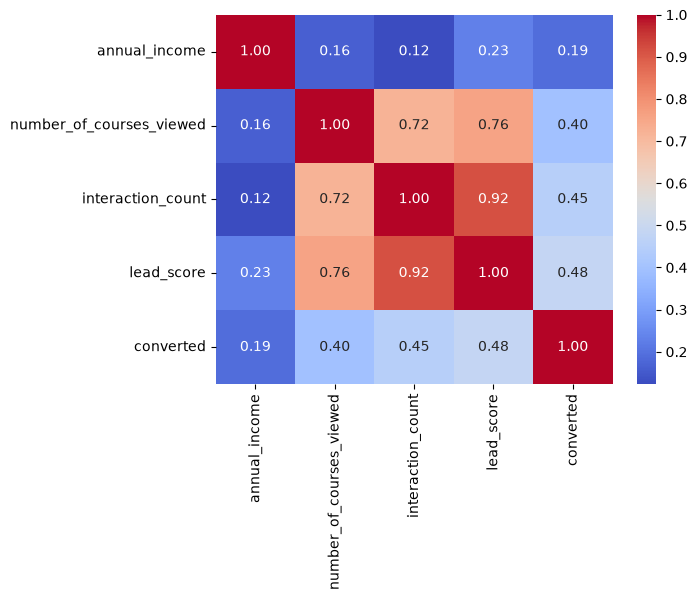

In [28]:
sns.heatmap(df[numerical_columns].corr(), annot=True, fmt=".2f", cmap="coolwarm");

In [26]:
df['converted'].value_counts(normalize=True)

converted
1    0.5766
0    0.4234
Name: proportion, dtype: float64

In [14]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

In [17]:
y_full_train = df_full_train['converted'].values
y_train = df_train['converted'].values
y_val = df_val['converted'].values
y_test = df_test['converted'].values

df_full_train = df_full_train.drop(columns=['converted'])
df_train = df_train.drop(columns=['converted'])
df_val = df_val.drop(columns=['converted'])
df_test = df_test.drop(columns=['converted'])

## Q1

In [29]:
from sklearn import metrics

In [31]:
numerical_columns.remove('converted')

In [32]:
numerical_columns

['annual_income',
 'number_of_courses_viewed',
 'interaction_count',
 'lead_score']

In [36]:
for col in numerical_columns:
    y_true = y_train
    y_score = df_train[col].values
    fpr, tpr, thresholds = metrics.roc_curve(y_true, y_score)
    print(f'AUC for {col}: {metrics.auc(fpr, tpr)}')

AUC for annual_income: 0.6081977776250831
AUC for number_of_courses_viewed: 0.7229894623989618
AUC for interaction_count: 0.7649203047563227
AUC for lead_score: 0.7882254810906102


## Q2

In [86]:
pipe = Pipeline([
    ('dv', DictVectorizer(sparse=False)),
    ('model', LogisticRegression(solver='liblinear', C=1.0, max_iter=1000, random_state=42))
])

In [87]:
pipe.fit(df_train.to_dict(orient='records'), y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('dv', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
,"sparse sparse: bool, default=TrueWhether transform should produce scipy.sparse matrices.",False
,"dtype dtype: dtype, default=np.float64The type of feature values. Passed to Numpy array/scipy.sparse matrixconstructors as the dtype argument.",<class 'numpy.float64'>
,"separator separator: str, default=""=""Separator string used when constructing new features for one-hotcoding.",'='
,"sort sort: bool, default=TrueWhether ``feature_names_`` and ``vocabulary_`` should besorted when fitting.",True
Name,Type,Value


In [102]:
y_pred_proba = pipe.predict_proba(df_val.to_dict(orient='records'))[:, 1]

In [92]:
y_pred = pipe.predict(df_val.to_dict(orient='records'))

In [89]:
fpr, tpr, thresholds = metrics.roc_curve(y_val, y_pred)

print(f'AUC for val dataset: {metrics.auc(fpr, tpr):.3f}')

AUC for val dataset: 0.721


In [90]:
from sklearn.metrics import confusion_matrix

In [96]:
confusion_matrix(y_val, y_pred)

array([[120, 208],
       [ 51, 421]])

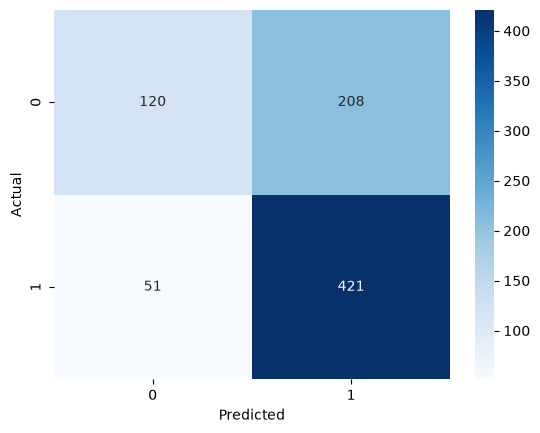

In [105]:
sns.heatmap(confusion_matrix(y_val, y_pred), annot=True, fmt="d", cmap="Blues")
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

In [94]:
tn, fp, fn, tp = confusion_matrix(y_val, y_pred).ravel().tolist()

In [106]:
precision = tp / (tp + fp)
recall = tp / (tp + fn)

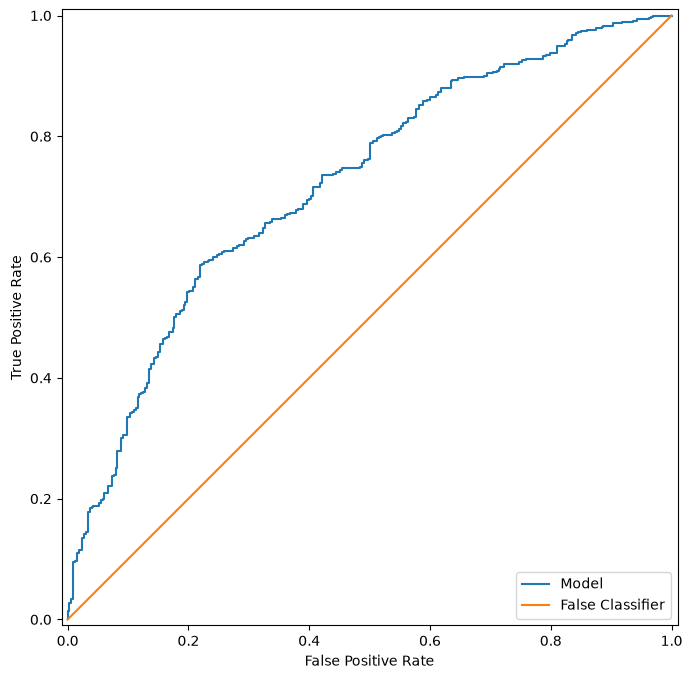

In [128]:
from sklearn.metrics import RocCurveDisplay, roc_curve

y_score = pipe.decision_function(df_val.to_dict(orient='records'))

fpr, tpr, _ = roc_curve(y_val, y_score, pos_label=pipe.classes_[1])
roc_display = RocCurveDisplay(fpr=fpr, tpr=tpr)

y_score_i = np.zeros_like(y_val)

fpr_i, tpr_i, _ = roc_curve(y_val, y_score_i, pos_label=pipe.classes_[1])
roc_display_i = RocCurveDisplay(fpr=fpr_i, tpr=tpr_i)

fig, ax1 = plt.subplots(1, 1, figsize=(8, 8))

roc_display.plot(ax=ax1)
roc_display_i.plot(ax=ax1)

plt.legend(['Model', 'False Classifier'], loc='lower right')

plt.show()

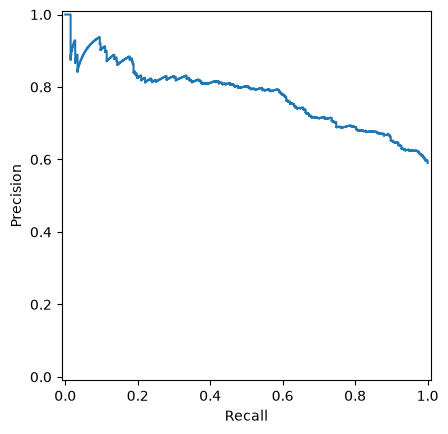

In [108]:
from sklearn.metrics import PrecisionRecallDisplay, precision_recall_curve

prec, recall, _ = precision_recall_curve(y_val, y_score, pos_label=pipe.classes_[1])
pr_display = PrecisionRecallDisplay(precision=prec, recall=recall).plot()

## Q3

In [45]:
scores = []

thresholds = np.linspace(0, 1, 101)

for t in thresholds:
    actual_positive = (y_val == 1)
    actual_negative = (y_val == 0)
    
    predict_positive = (y_pred >= t)
    predict_negative = (y_pred < t)

    tp = (predict_positive & actual_positive).sum()
    tn = (predict_negative & actual_negative).sum()

    fp = (predict_positive & actual_negative).sum()
    fn = (predict_negative & actual_positive).sum()
    
    scores.append((t, tp, fp, fn, tn))

In [47]:
columns = ['threshold', 'tp', 'fp', 'fn', 'tn']
df_scores = pd.DataFrame(scores, columns=columns)

In [48]:
df_scores['precision'] = df_scores['tp'] / (df_scores['tp'] + df_scores['fp'])
df_scores['recall'] = df_scores['tp'] / (df_scores['tp'] + df_scores['fn'])

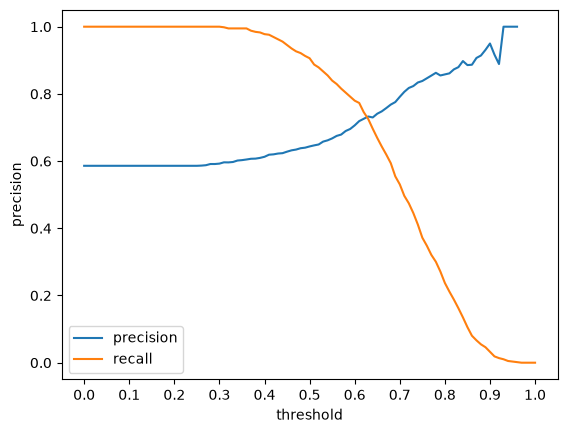

In [57]:
sns.lineplot(data=df_scores, x='threshold', y='precision', label='precision')
sns.lineplot(data=df_scores, x='threshold', y='recall', label='recall')
plt.xticks(np.arange(0, 1.1, 0.1))
plt.show()

## Q4

In [58]:
df_scores['f1'] = 2 * df_scores['precision'] * df_scores['recall'] / (df_scores['precision'] + df_scores['recall'])

<Axes: >

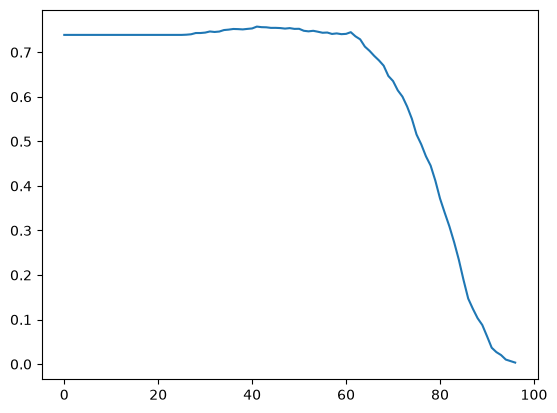

In [60]:
df_scores['f1'].plot()

In [63]:
df_scores.loc[df_scores['f1'].idxmax()]

threshold      0.410000
tp           572.000000
fp           352.000000
fn            14.000000
tn            62.000000
precision      0.619048
recall         0.976109
f1             0.757616
Name: 41, dtype: float64

## Q5

In [66]:
from sklearn.model_selection import KFold
from sklearn.model_selection import cross_val_score

In [65]:
cv = KFold(n_splits=5, shuffle=True, random_state=1)

In [71]:
scores = []

for train_idx, val_idx in cv.split(df_full_train):
    df_train = df_full_train.iloc[train_idx]
    df_val = df_full_train.iloc[val_idx]

    y_train = y_full_train[train_idx]
    y_val = y_full_train[val_idx]

    model = pipe.fit(df_train.to_dict(orient='records'), y_train)
    y_pred = model.predict_proba(df_val.to_dict(orient='records'))[:, 1]

    fpr, tpr, thresholds = metrics.roc_curve(y_val, y_pred)
    scores.append(metrics.auc(fpr, tpr))

    print(f'AUC for val dataset: {metrics.auc(fpr, tpr):.3f}')

AUC for val dataset: 0.731
AUC for val dataset: 0.730
AUC for val dataset: 0.736
AUC for val dataset: 0.741
AUC for val dataset: 0.721


In [75]:
print(f"{np.std(scores):.3f}")

0.007


## Q6

In [76]:
from sklearn.model_selection import GridSearchCV

In [78]:
C = [0.000001, 0.001, 1]

parameters = {"model__C": C}

gs = GridSearchCV(pipe, parameters, cv=cv, scoring='roc_auc')

In [79]:
gs.fit(df_full_train.to_dict(orient='records'), y_full_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...liblinear'))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__C': [1e-06, 0.001, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'roc_auc'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",KFold(n_split... shuffle=True)
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbosity of inf

In [82]:
gs.best_score_, gs.best_params_

(np.float64(0.7491721776030379), {'model__C': 0.001})